**Practical**

---


Scrap and create your own dataset, do feature engineering on dataset (encoding), and use data visualization.

***Load the datasets from Drive***

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATASET_DIR = "/content/drive/MyDrive/AIML Project"
laps_df   = pd.read_csv(f"{DATASET_DIR}/raw_laps_2024.csv")
stints_df = pd.read_csv(f"{DATASET_DIR}/raw_stints_2024.csv")

print(laps_df.shape, stints_df.shape)

Mounted at /content/drive
(26629, 18) (1309, 10)


***Merge the datasets***

In [ ]:
rows = []

# loop over every stint (driver + stint number) in every race
for (race, driver, stint), g in stints_df.groupby(["race", "driver_number", "stint_number"]):
    lap_start = g["lap_start"].iloc[0]
    lap_end   = g["lap_end"].iloc[0]

    # get only the laps of this race that belong to this stint
    stint_laps = laps_df[(laps_df["race"] == race) &
                         (laps_df["driver_number"] == driver) &
                         (laps_df["lap_number"] >= lap_start) &
                         (laps_df["lap_number"] <= lap_end)].sort_values("lap_number")

    if len(stint_laps) < 5:      # ignore tiny stints (crashes, late pit entries)
        continue

    for _, lap in stint_laps.iterrows():
        rows.append({
            "race": race,
            "circuit": g["circuit"].iloc[0],
            "driver_number": driver,
            "compound": g["compound"].iloc[0],
            "lap_duration": lap["lap_duration"],
            "s1": lap["duration_sector_1"],
            "s2": lap["duration_sector_2"],
            "s3": lap["duration_sector_3"],
            "tyre_age": lap["lap_number"] - lap_start + g["tyre_age_at_start"].iloc[0],  # laps used
            "stint_length": lap_end - lap_start + 1,                                     # total tyre life
            "RUL": lap_end - lap["lap_number"],                                          # target: laps remaining
        })

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(26461, 11)


,race,circuit,driver_number,compound,lap_duration,s1,s2,s3,tyre_age,stint_length,RUL
0,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,99.877,25.002,39.931,34.944,0.0,29.0,28.0
1,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,114.938,18.209,54.569,42.160,1.0,29.0,27.0
2,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,98.051,23.196,41.997,32.858,2.0,29.0,26.0
3,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,89.504,18.166,38.187,33.151,3.0,29.0,25.0
4,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,89.813,18.056,37.945,33.812,4.0,29.0,24.0


***Cleaning***

In [ ]:
# checking null values before cleaning
print(df.isnull().sum())

# removing rows with missing sector times or lap time
df = df.dropna(subset=["lap_duration", "s1", "s2", "s3"])

# removing impossible lap times (real F1 laps are 55–130 seconds)
df = df[df["lap_duration"] > 50]
df = df[df["lap_duration"] < 150]

# resetting row numbers after removing rows
df = df.reset_index(drop=True)

# creating classification label: 1 = tyre dies this lap (driver pits), 0 = continues
df["pit_next_lap"] = (df["RUL"] == 0).astype(int)

print(df.shape)
df.head()

race               0
circuit            0
driver_number      0
compound           0
lap_duration      31
s1               133
s2                 4
s3                21
tyre_age           0
stint_length       0
RUL                0
dtype: int64
(26206, 12)


,race,circuit,driver_number,compound,lap_duration,s1,s2,s3,tyre_age,stint_length,RUL,pit_next_lap
0,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,99.877,25.002,39.931,34.944,0.0,29.0,28.0,0
1,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,114.938,18.209,54.569,42.160,1.0,29.0,27.0,0
2,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,98.051,23.196,41.997,32.858,2.0,29.0,26.0,0
3,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,89.504,18.166,38.187,33.151,3.0,29.0,25.0,0
4,Abu Dhabi Grand Prix,Yas Marina Circuit,1,MEDIUM,89.813,18.056,37.945,33.812,4.0,29.0,24.0,0


***Encoding***

In [ ]:
# ONE-HOT ENCODING the tyre compound (SOFT/MEDIUM/HARD -> 3 binary columns)
df = pd.get_dummies(df, columns=["compound"], prefix="tyre", dtype=int)

# LABEL ENCODING the circuit (24 circuits -> numbers 0 to 23)
# used because one-hot would create 24 extra columns
from sklearn.preprocessing import LabelEncoder
df["circuit_code"] = LabelEncoder().fit_transform(df["circuit"])

# dropping the original text column, we keep only the encoded version
df = df.drop(columns=["race"])   # race name dropped, circuit_code carries the info
df.head()

,circuit,driver_number,lap_duration,s1,s2,s3,tyre_age,stint_length,RUL,pit_next_lap,tyre_HARD,tyre_INTERMEDIATE,tyre_MEDIUM,tyre_SOFT,tyre_WET,circuit_code
0,Yas Marina Circuit,1,99.877,25.002,39.931,34.944,0.0,29.0,28.0,0,0,0,1,0,0,22
1,Yas Marina Circuit,1,114.938,18.209,54.569,42.160,1.0,29.0,27.0,0,0,0,1,0,0,22
2,Yas Marina Circuit,1,98.051,23.196,41.997,32.858,2.0,29.0,26.0,0,0,0,1,0,0,22
3,Yas Marina Circuit,1,89.504,18.166,38.187,33.151,3.0,29.0,25.0,0,0,0,1,0,0,22
4,Yas Marina Circuit,1,89.813,18.056,37.945,33.812,4.0,29.0,24.0,0,0,0,1,0,0,22


***Binning***

In [ ]:
# BINNING tyre age into life stages (fresh -> dead)
bins   = [0, 8, 16, 24, 100]
labels = ["fresh", "medium", "worn", "dead"]
df["tyre_life_stage"] = pd.cut(df["tyre_age"], bins=bins, labels=labels,include_lowest=True)

# BINNING RUL into classes for easier analysis (short/medium/long life left)
rul_bins   = [-1, 3, 10, 100]
rul_labels = ["pit_soon", "pit_mid", "pit_late"]
df["rul_group"] = pd.cut(df["RUL"], bins=rul_bins, labels=rul_labels)

df["tyre_life_stage"].value_counts()

df.head()

,circuit,driver_number,lap_duration,s1,s2,s3,tyre_age,stint_length,RUL,pit_next_lap,tyre_HARD,tyre_INTERMEDIATE,tyre_MEDIUM,tyre_SOFT,tyre_WET,circuit_code,tyre_life_stage,rul_group
0,Yas Marina Circuit,1,99.877,25.002,39.931,34.944,0.0,29.0,28.0,0,0,0,1,0,0,22,fresh,pit_late
1,Yas Marina Circuit,1,114.938,18.209,54.569,42.160,1.0,29.0,27.0,0,0,0,1,0,0,22,fresh,pit_late
2,Yas Marina Circuit,1,98.051,23.196,41.997,32.858,2.0,29.0,26.0,0,0,0,1,0,0,22,fresh,pit_late
3,Yas Marina Circuit,1,89.504,18.166,38.187,33.151,3.0,29.0,25.0,0,0,0,1,0,0,22,fresh,pit_late
4,Yas Marina Circuit,1,89.813,18.056,37.945,33.812,4.0,29.0,24.0,0,0,0,1,0,0,22,fresh,pit_late


***Scaling and Standardization***

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# numeric features that go into the model
features = ["lap_duration", "s1", "s2", "s3", "tyre_age", "stint_length", "circuit_code"]

# STANDARDIZATION (mean=0, std=1) -> used for Ridge/Lasso/Gradient Descent
scaler_std = StandardScaler()
df_std = df.copy()
df_std[features] = scaler_std.fit_transform(df[features])

# NORMALIZATION (0 to 1 range) -> shown for comparison, MinMaxScaler
scaler_mm = MinMaxScaler()
df_norm = df.copy()
df_norm[features] = scaler_mm.fit_transform(df[features])

print("Standardized (mean ~0):")
print(df_std[features].mean().round(3))
print("\nNormalized (0 to 1):")
print(df_norm[features].min(), df_norm[features].max())

df_std.head()

Standardized (mean ~0):
lap_duration    0.0
s1              0.0
s2             -0.0
s3              0.0
tyre_age       -0.0
stint_length    0.0
circuit_code   -0.0
dtype: float64

Normalized (0 to 1):
lap_duration    0.0
s1              0.0
s2              0.0
s3              0.0
tyre_age        0.0
stint_length    0.0
circuit_code    0.0
dtype: float64 lap_duration    1.0
s1              1.0
s2              1.0
s3              1.0
tyre_age        1.0
stint_length    1.0
circuit_code    1.0
dtype: float64


,circuit,driver_number,lap_duration,s1,s2,s3,tyre_age,stint_length,RUL,pit_next_lap,tyre_HARD,tyre_INTERMEDIATE,tyre_MEDIUM,tyre_SOFT,tyre_WET,circuit_code,tyre_life_stage,rul_group
0,Yas Marina Circuit,1,0.683050,-0.529266,0.699583,0.990049,-1.249033,0.03462,28.0,0,0,0,1,0,0,1.497802,fresh,pit_late
1,Yas Marina Circuit,1,1.861726,-1.570145,2.726064,1.992182,-1.160832,0.03462,27.0,0,0,0,1,0,0,1.497802,fresh,pit_late
2,Yas Marina Circuit,1,0.540147,-0.805996,0.985600,0.700352,-1.072632,0.03462,26.0,0,0,0,1,0,0,1.497802,fresh,pit_late
3,Yas Marina Circuit,1,-0.128743,-1.576734,0.458145,0.741043,-0.984431,0.03462,25.0,0,0,0,1,0,0,1.497802,fresh,pit_late
4,Yas Marina Circuit,1,-0.104561,-1.593589,0.424642,0.832841,-0.896231,0.03462,24.0,0,0,0,1,0,0,1.497802,fresh,pit_late


***Visualization***

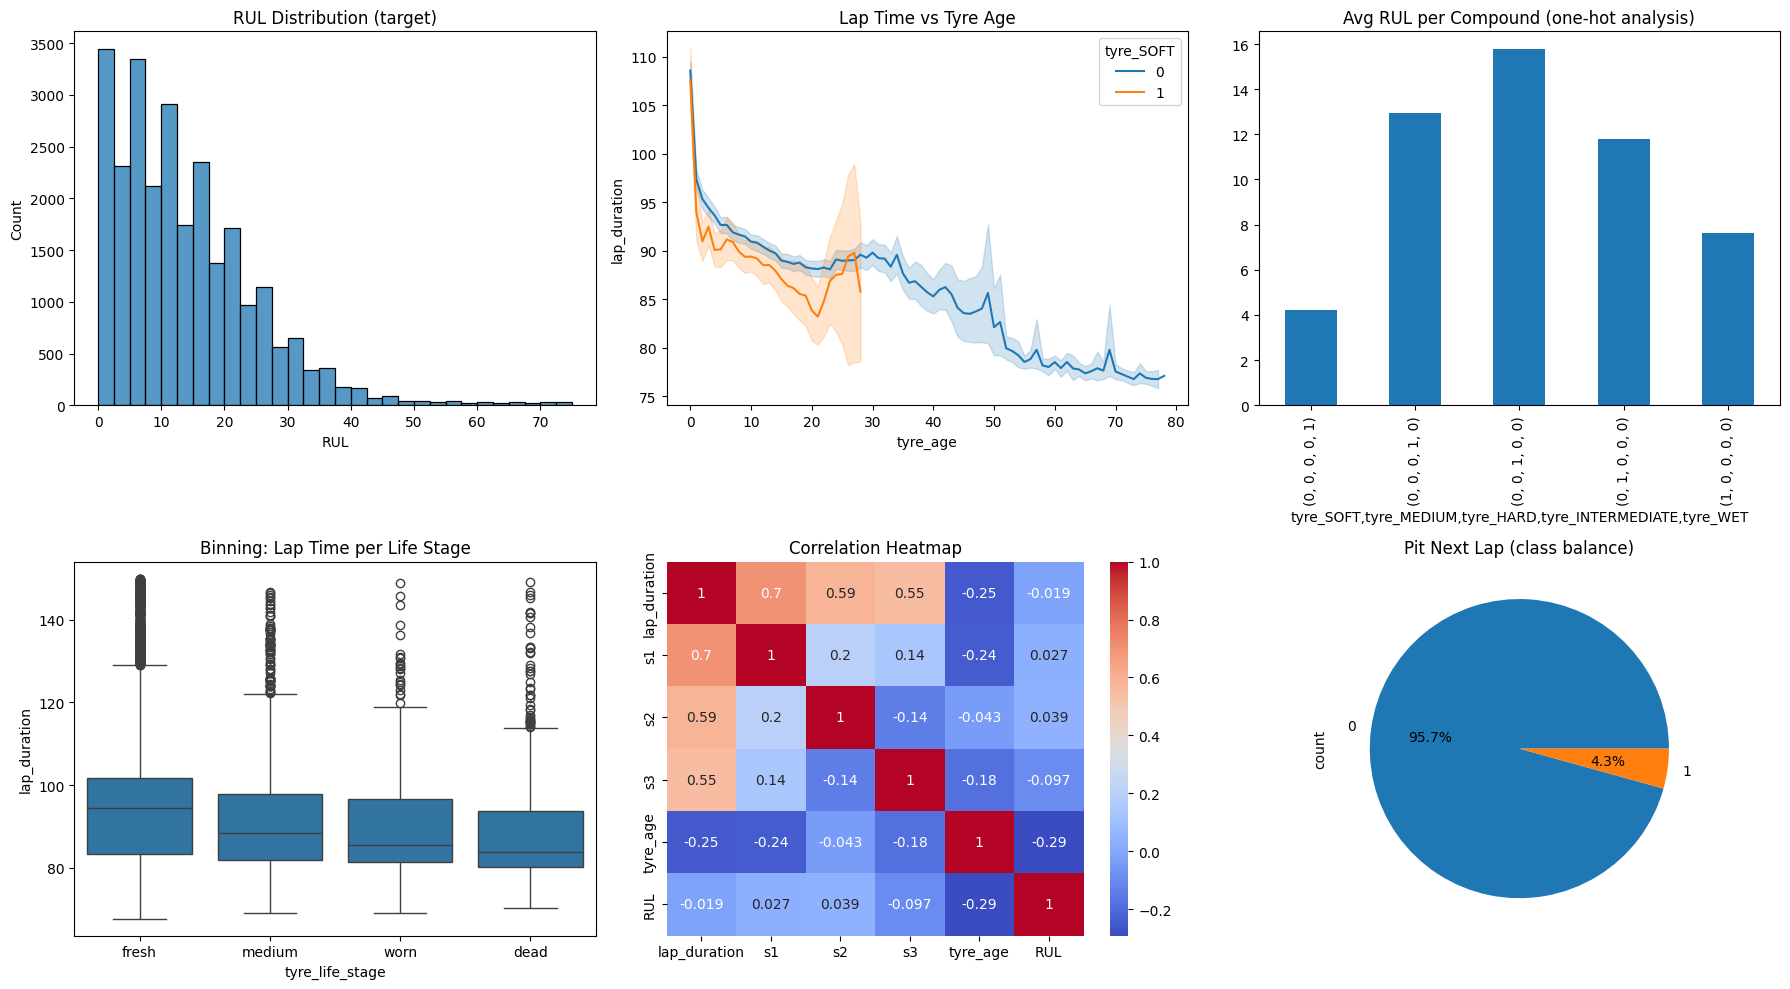

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. target distribution
sns.histplot(df["RUL"], bins=30, ax=axes[0,0]).set_title("RUL Distribution (target)")

# 2. tyre degradation curve -> proves polynomial regression is needed
sns.lineplot(data=df, x="tyre_age", y="lap_duration", hue="tyre_SOFT",
             ax=axes[0,1]).set_title("Lap Time vs Tyre Age")

# 3. one-hot encoding result -> average RUL per compound
df.groupby(["tyre_SOFT","tyre_MEDIUM","tyre_HARD","tyre_INTERMEDIATE", "tyre_WET"])["RUL"].mean().plot.bar(ax=axes[0,2])
axes[0,2].set_title("Avg RUL per Compound (one-hot analysis)")

# 4. binned feature analysis -> lap time per tyre life stage
sns.boxplot(data=df, x="tyre_life_stage", y="lap_duration", ax=axes[1,0]).set_title("Binning: Lap Time per Life Stage")

# 5. correlation heatmap -> shows collinearity (why Ridge/Lasso)
corr_cols = ["lap_duration","s1","s2","s3","tyre_age","RUL"]
sns.heatmap(df[corr_cols].corr(), annot=True, cmap="coolwarm", ax=axes[1,1]).set_title("Correlation Heatmap")

# 6. class balance for classification task
df["pit_next_lap"].value_counts().plot.pie(autopct="%1.1f%%", ax=axes[1,2]).set_title("Pit Next Lap (class balance)")

plt.tight_layout()
plt.show()

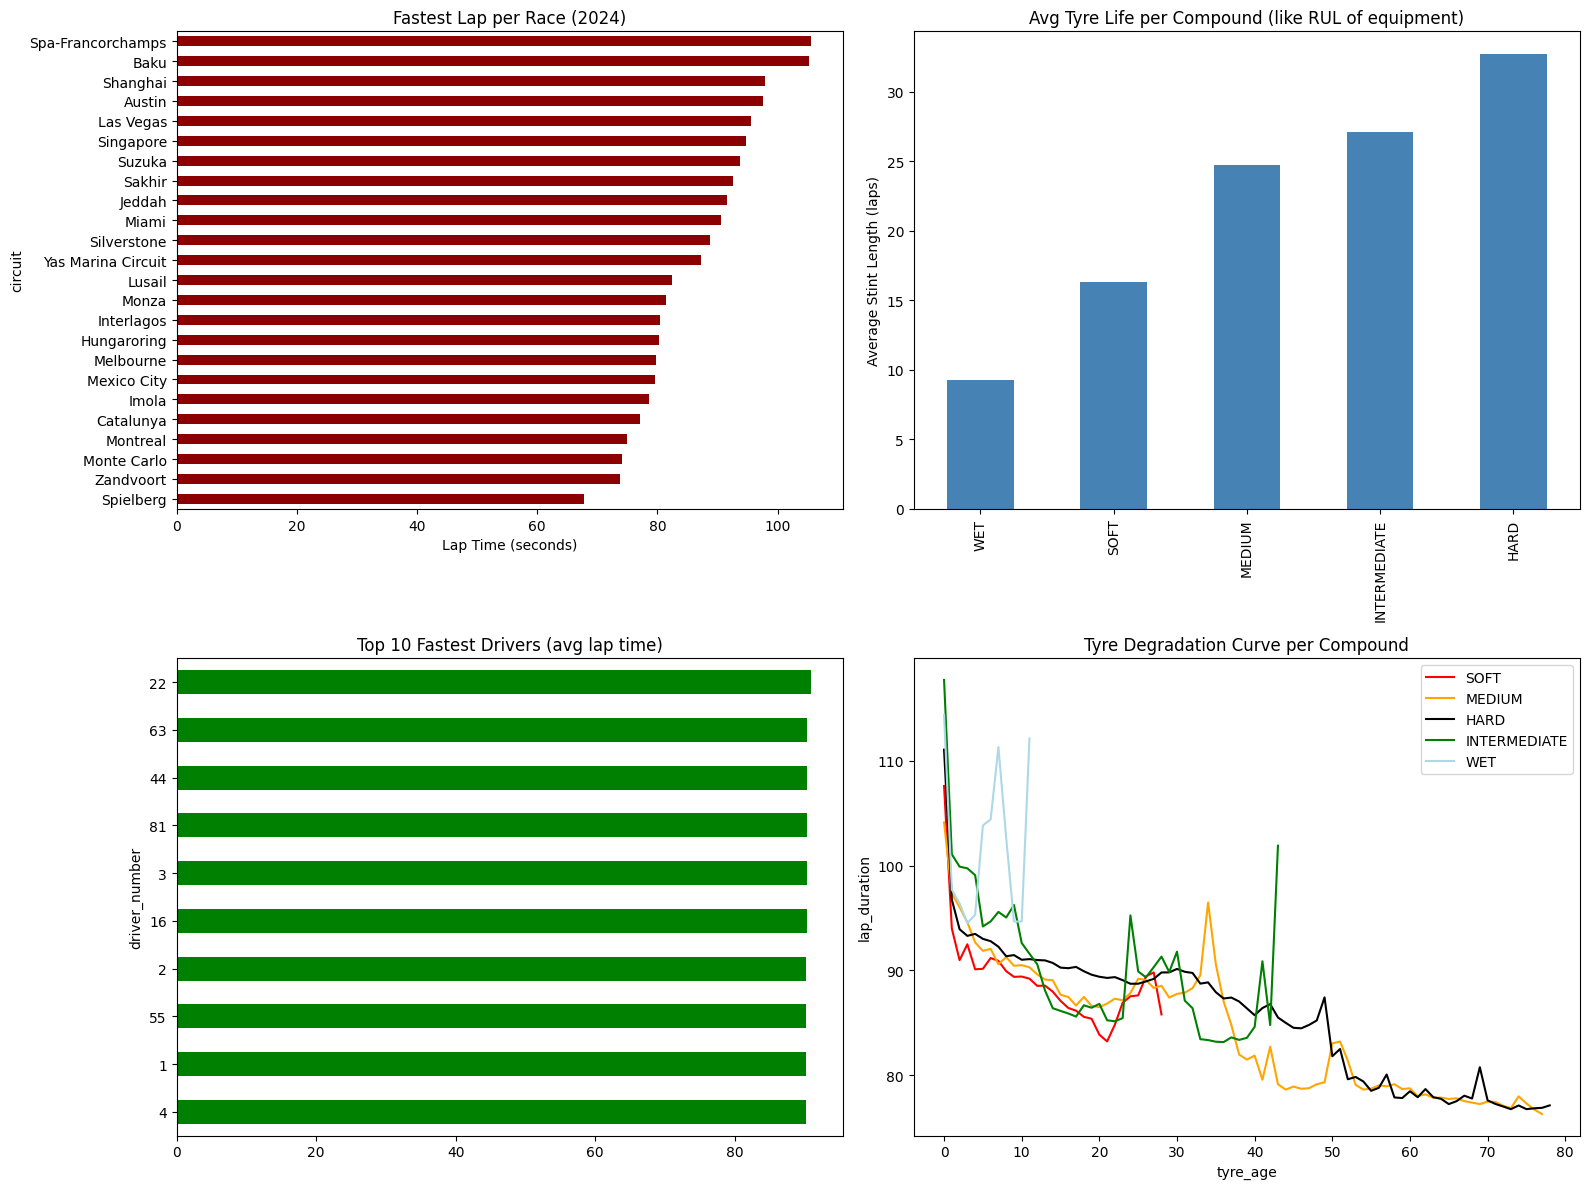

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. FASTEST LAP IN EACH RACE (per circuit)
fastest = df.groupby("circuit")["lap_duration"].min().sort_values()
fastest.plot.barh(ax=axes[0,0], color="darkred")
axes[0,0].set_title("Fastest Lap per Race (2024)")
axes[0,0].set_xlabel("Lap Time (seconds)")

# 2. AVERAGE TYRE LIFE (stint length) PER COMPOUND -> the "equipment durability" chart
# We filter for only the rows where exactly one of HARD, MEDIUM, or SOFT is 1, and map them to friendly labels
compounds = []
for col, name in [("tyre_HARD", "HARD"), ("tyre_MEDIUM", "MEDIUM"), ("tyre_SOFT", "SOFT"),("tyre_WET", "WET"),("tyre_INTERMEDIATE", "INTERMEDIATE")]:
    avg_life = df[df[col] == 1]["stint_length"].mean()
    compounds.append((name, avg_life))

compound_life = pd.Series(dict(compounds))
compound_life.sort_values().plot.bar(ax=axes[0,1], color="steelblue")
axes[0,1].set_title("Avg Tyre Life per Compound (like RUL of equipment)")
axes[0,1].set_ylabel("Average Stint Length (laps)")

# 3. TOP 10 FASTEST DRIVERS (avg lap time in a race)
top_drivers = df.groupby("driver_number")["lap_duration"].mean().nsmallest(10)
top_drivers.sort_values().plot.barh(ax=axes[1,0], color="green")
axes[1,0].set_title("Top 10 Fastest Drivers (avg lap time)")

# 4. DEGRADATION CURVES PER COMPOUND -> soft dies fast, hard survives
for col, name, color in [("tyre_SOFT","SOFT","red"), ("tyre_MEDIUM","MEDIUM","orange"), ("tyre_HARD","HARD","black"),("tyre_INTERMEDIATE", "INTERMEDIATE", "green"),("tyre_WET", "WET", "lightblue")]:
    subset = df[df[col] == 1]
    sns.lineplot(data=subset, x="tyre_age", y="lap_duration",
                 label=name, color=color, errorbar=None, ax=axes[1,1])
axes[1,1].set_title("Tyre Degradation Curve per Compound")
axes[1,1].legend()

plt.tight_layout()
plt.show()

***Saving final .CSV file into DRIVE***





In [ ]:
df.to_csv(f"{DATASET_DIR}/laps_2024.csv", index=False)
df_std.to_csv(f"{DATASET_DIR}/laps_2024_std.csv", index=False)
df_norm.to_csv(f"{DATASET_DIR}/laps_2024_norm.csv", index=False)
